# 03 · A convolution layer from scratch (forward, backward, gradient check)

This notebook implements a 2-D convolution layer in NumPy and verifies it three ways: the forward pass against SciPy (and PyTorch when installed), the backward pass against numerical gradients, and the input gradient against the closed-form "rotated kernel" result. Section 5 rewrites the layer with im2col, and section 6 trains a small denoiser built only from this layer.

Shapes (PyTorch convention): input `x` is `(N, C_in, H, W)`, weights `w` are `(C_out, C_in, k, k)`, bias `b` is `(C_out,)`.

Runs on CPU. PyTorch is optional; without it, the SciPy references and the numerical gradient check do the verifying.

In [1]:
import os, glob, time
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate2d, convolve2d     # independent references (no deep-learning library)

rng = np.random.default_rng(0)
try:
    import torch
    import torch.nn.functional as F
    torch.set_default_dtype(torch.float64)   # float64 makes gradient checks meaningful
    HAVE_TORCH = True
except ImportError:
    HAVE_TORCH = False
print("PyTorch available:", HAVE_TORCH, "(if not, the PyTorch comparisons are skipped and SciPy references are used)")

PyTorch available: False (if not, the PyTorch comparisons are skipped and SciPy references are used)


## 1 · The maths

Notation: input $x \in \mathbb{R}^{N \times C \times H \times W}$, kernels $w \in \mathbb{R}^{O \times C \times k \times k}$,
bias $b \in \mathbb{R}^{O}$, stride $s$, zero padding $p$, and $\tilde x$ the padded input.

**Forward.** Each output value is a dot product between one kernel and one patch of the input:

$$y_{n,o,i,j} = b_o + \sum_{c=1}^{C}\sum_{u=0}^{k-1}\sum_{v=0}^{k-1} w_{o,c,u,v}\,\tilde x_{n,c,\,si+u,\,sj+v},
\qquad H_{out} = \left\lfloor \frac{H + 2p - k}{s} \right\rfloor + 1$$

This is a **cross-correlation** (the kernel is not flipped). Deep-learning "convolution" layers compute exactly this;
it does not matter for learning, because a flipped kernel is just another set of weights the optimiser can find.

Write $g_{n,o,i,j} = \partial L / \partial y_{n,o,i,j}$ for the gradient arriving from the layer above.

**Bias.** $b_o$ is added to every output position of channel $o$, so its gradient sums the upstream gradient over them:

$$\frac{\partial L}{\partial b_o} = \sum_{n,i,j} g_{n,o,i,j}$$

**Weights.** $w_{o,c,u,v}$ multiplies $\tilde x_{n,c,si+u,sj+v}$ at every position, so

$$\frac{\partial L}{\partial w_{o,c,u,v}} = \sum_{n,i,j} g_{n,o,i,j}\,\tilde x_{n,c,\,si+u,\,sj+v}$$

which is a cross-correlation of the input with the upstream gradient (dilated by the stride).

**Input.** Input pixel $\tilde x_{n,c,a,b}$ contributes to every output whose window covers it, i.e. where $a = si + u$, $b = sj + v$:

$$\frac{\partial L}{\partial \tilde x_{n,c,a,b}} = \sum_{o}\sum_{u,v} g_{n,o,\frac{a-u}{s},\frac{b-v}{s}}\; w_{o,c,u,v}
\quad\text{(terms with non-integer or out-of-range indices are zero)}$$

For $s = 1$ substitute $u' = k - 1 - u$: the sum becomes $\sum_o \sum_{u',v'} g_{n,o,a-k+1+u',\,b-k+1+v'}\,
w_{o,c,k-1-u',k-1-v'}$, a **full** cross-correlation of $g$ (zero-padded by $k-1$) with the kernel **rotated by 180°**.
The rotation appears because a forward window slides *over* the input, so the input's view of the output runs the
kernel indices backwards. Equivalently, it is a full *convolution* of $g$ with the unrotated $w$, summed over $o$,
and with in/out channels swapped compared with the forward pass. Finally, remove the padding: $\partial L/\partial x$
is the centre $H \times W$ of $\partial L / \partial \tilde x$.

## 2 · Forward pass (naive loops first — clarity over speed)

The loop runs over output positions; at each one, `np.tensordot` takes the dot product of the input patch with every kernel at once. The result is checked against SciPy's `correlate2d` (summed over input channels) on three shape, stride and padding cases.

In [2]:
def conv2d_forward_naive(x, w, b, stride=1, pad=0):
    """Returns (y, cache). Explicit loop over output positions; each step is one dot product per kernel."""
    N, C, H, W = x.shape
    O, _, k, _ = w.shape
    xp = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad)))
    Ho, Wo = (H + 2 * pad - k) // stride + 1, (W + 2 * pad - k) // stride + 1
    y = np.zeros((N, O, Ho, Wo))
    for i in range(Ho):
        for j in range(Wo):
            patch = xp[:, :, i * stride:i * stride + k, j * stride:j * stride + k]       # (N, C, k, k)
            y[:, :, i, j] = np.tensordot(patch, w, axes=([1, 2, 3], [1, 2, 3])) + b     # (N, O)
    return y, (x, w, b, stride, pad)

def relu_forward(x):
    return np.maximum(x, 0), x

def relu_backward(dout, cache):
    return dout * (cache > 0)

In [3]:
def conv_reference_scipy(x, w, b, stride, pad):
    """Independent reference: SciPy's 2-D cross-correlation, summed over input channels."""
    xp = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad)))
    out = np.stack([np.stack([sum(correlate2d(xp[n, c], w[o, c], mode="valid") for c in range(x.shape[1])) + b[o]
                              for o in range(w.shape[0])]) for n in range(x.shape[0])])
    return out[:, :, ::stride, ::stride]

CASES = [(2, 3, 7, 7, 4, 3, 1, 1), (1, 1, 8, 6, 2, 3, 2, 0), (2, 2, 9, 9, 3, 5, 1, 2)]
for (N, Cin, H, W, Cout, k, s, p) in CASES:
    x = rng.standard_normal((N, Cin, H, W)); w = rng.standard_normal((Cout, Cin, k, k)); b = rng.standard_normal(Cout)
    y, _ = conv2d_forward_naive(x, w, b, stride=s, pad=p)
    y_ref = conv_reference_scipy(x, w, b, s, p)
    assert y.shape == y_ref.shape and np.allclose(y, y_ref, atol=1e-10), np.abs(y - y_ref).max()
    if HAVE_TORCH:
        y_t = F.conv2d(torch.tensor(x), torch.tensor(w), torch.tensor(b), stride=s, padding=p).numpy()
        assert np.allclose(y, y_t, atol=1e-8), np.abs(y - y_t).max()
print("forward matches SciPy" + (" and PyTorch" if HAVE_TORCH else "") + f" on {len(CASES)} shape/stride/padding cases")

forward matches SciPy on 3 shape/stride/padding cases


## 3 · Backward pass + checks

The backward pass runs the forward loop in reverse: every output position sends its gradient to the kernel (`dw`) and to the patch it was computed from (`dx`, accumulated because windows overlap). It is checked with central-difference numerical gradients on the scalar loss $L = \sum y \cdot g$ (so $\partial L / \partial y = g$), in float64, using a norm-based relative error. A deliberately wrong version (kernel not rotated) shows that the check catches real mistakes.

In [4]:
def conv2d_backward_naive(dout, cache):
    """Returns dx, dw, db with the same shapes as x, w, b. Same loop as the forward pass, run in reverse:
    every output position sends its gradient back to the kernel (dw) and to the patch it was computed from (dx)."""
    x, w, b, stride, pad = cache
    N, C, H, W = x.shape
    O, _, k, _ = w.shape
    xp = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad)))
    dxp, dw = np.zeros_like(xp), np.zeros_like(w)
    db = dout.sum(axis=(0, 2, 3))
    Ho, Wo = dout.shape[2:]
    for i in range(Ho):
        for j in range(Wo):
            sl = (slice(None), slice(None), slice(i * stride, i * stride + k), slice(j * stride, j * stride + k))
            g = dout[:, :, i, j]                                        # (N, O)
            dw += np.tensordot(g, xp[sl], axes=([0], [0]))              # (O, C, k, k)
            dxp[sl] += np.tensordot(g, w, axes=([1], [0]))              # (N, C, k, k), accumulated (windows overlap)
    dx = dxp[:, :, pad:pad + H, pad:pad + W]                             # un-pad
    return dx, dw, db

In [5]:
def numerical_grad(f, arr, eps=1e-6):
    """Central differences: (f(arr + eps*e_i) - f(arr - eps*e_i)) / 2eps for every element i (arr mutated in place)."""
    grad = np.zeros_like(arr)
    it = np.nditer(arr, flags=["multi_index"])
    for _ in it:
        idx = it.multi_index
        old = arr[idx]
        arr[idx] = old + eps; fp = f()
        arr[idx] = old - eps; fm = f()
        arr[idx] = old
        grad[idx] = (fp - fm) / (2 * eps)
    return grad

def rel_error(a, b):
    """Norm-based relative error ||a - b|| / (||a|| + ||b||). An element-wise max is dominated by rounding
    noise wherever the true gradient is ~0 (with stride 2 some input pixels get exactly zero gradient)."""
    return np.linalg.norm(a - b) / max(1e-12, np.linalg.norm(a) + np.linalg.norm(b))

def max_abs_error(a, b):
    return np.max(np.abs(a - b))

# Gradient check on a scalar loss L = sum(y * g) for a random fixed g (so dL/dy = g), several strides/paddings
for (s, p) in [(1, 1), (2, 1), (2, 0)]:
    x = rng.standard_normal((2, 3, 6, 6)); w = rng.standard_normal((4, 3, 3, 3)); b = rng.standard_normal(4)
    y0, cache = conv2d_forward_naive(x, w, b, stride=s, pad=p)
    g = rng.standard_normal(y0.shape)
    loss = lambda: np.sum(conv2d_forward_naive(x, w, b, stride=s, pad=p)[0] * g)
    dx, dw, db = conv2d_backward_naive(g, cache)
    errs = {name: rel_error(analytic, numerical_grad(loss, arr)) for name, analytic, arr in [("dx", dx, x), ("dw", dw, w), ("db", db, b)]}
    print(f"stride {s}, pad {p}: " + ", ".join(f"{k} rel. error {v:.1e}" for k, v in errs.items()))
    assert max(errs.values()) < 1e-7
print("analytic gradients match numerical gradients")

# The check has teeth: a backward pass that forgets to rotate the kernel is caught immediately
x = rng.standard_normal((1, 2, 5, 5)); w = rng.standard_normal((3, 2, 3, 3)); b = np.zeros(3)
y0, cache = conv2d_forward_naive(x, w, b, 1, 1); g = rng.standard_normal(y0.shape)
wrong_dx = conv2d_backward_naive(g, (x, w[:, :, ::-1, ::-1].copy(), b, 1, 1))[0]
loss = lambda: np.sum(conv2d_forward_naive(x, w, b, 1, 1)[0] * g)
print(f"deliberately wrong kernel orientation: rel. error {rel_error(wrong_dx, numerical_grad(loss, x)):.2f} (caught)")

stride 1, pad 1: dx rel. error 4.0e-10, dw rel. error 2.8e-10, db rel. error 2.3e-10
stride 2, pad 1: dx rel. error 6.9e-10, dw rel. error 5.9e-10, db rel. error 1.7e-10
stride 2, pad 0: dx rel. error 2.9e-10, dw rel. error 3.1e-10, db rel. error 2.0e-10
analytic gradients match numerical gradients
deliberately wrong kernel orientation: rel. error 0.71 (caught)


In [6]:
# Same thing, checked against autograd (needs PyTorch)
if HAVE_TORCH:
    x = rng.standard_normal((2, 3, 6, 6)); w = rng.standard_normal((4, 3, 3, 3)); b = rng.standard_normal(4)
    for s, p in [(1, 1), (2, 1), (2, 0)]:
        xt = torch.tensor(x, requires_grad=True); wt = torch.tensor(w, requires_grad=True); bt = torch.tensor(b, requires_grad=True)
        yt = F.conv2d(xt, wt, bt, stride=s, padding=p)
        gt = torch.randn_like(yt); (yt * gt).sum().backward()
        _, cache = conv2d_forward_naive(x, w, b, stride=s, pad=p)
        dx, dw, db = conv2d_backward_naive(gt.numpy(), cache)
        assert np.allclose(dx, xt.grad.numpy()) and np.allclose(dw, wt.grad.numpy()) and np.allclose(db, bt.grad.numpy()), (s, p)
    print("backward matches autograd")
else:
    print("skipped: PyTorch not installed (the numerical gradient check above already verifies the backward pass)")

skipped: PyTorch not installed (the numerical gradient check above already verifies the backward pass)


## 4 · The rotated-kernel result, numerically

For stride 1, the input gradient is computed three independent ways: the backward pass above, a full cross-correlation of the upstream gradient with the kernel rotated 180° (with input and output channels swapped), and a full convolution with the unrotated kernel. When PyTorch is available, it is also compared with `F.conv_transpose2d`. Agreement confirms the derivation in section 1.

In [7]:
# For stride 1: dL/dx = full convolution of the upstream gradient with the kernel, summed over output channels,
# i.e. a full cross-correlation with the 180-degree-rotated kernel. Checked independently of the backward code.
N, Cin, H, W, Cout, k, p = 2, 3, 7, 7, 4, 3, 1
x = rng.standard_normal((N, Cin, H, W)); w = rng.standard_normal((Cout, Cin, k, k)); b = rng.standard_normal(Cout)
y, cache = conv2d_forward_naive(x, w, b, stride=1, pad=p)
g = rng.standard_normal(y.shape)
dx, _, _ = conv2d_backward_naive(g, cache)

rot = w[:, :, ::-1, ::-1]                                          # kernel rotated by 180 degrees
dxp_rot = np.stack([np.stack([sum(correlate2d(g[n, o], rot[o, c], mode="full") for o in range(Cout))
                              for c in range(Cin)]) for n in range(N)])   # full correlation with rotated kernel
dx_rot = dxp_rot[:, :, p:p + H, p:p + W]                           # remove the padding
dxp_conv = np.stack([np.stack([sum(convolve2d(g[n, o], w[o, c], mode="full") for o in range(Cout))
                               for c in range(Cin)]) for n in range(N)])  # same thing as a true convolution
assert np.allclose(dx, dx_rot) and np.allclose(dx, dxp_conv[:, :, p:p + H, p:p + W])
if HAVE_TORCH:
    assert np.allclose(dx, F.conv_transpose2d(torch.tensor(g), torch.tensor(w), padding=p).numpy())
print("dL/dx == full correlation with the 180-degree-rotated kernel == full convolution with the kernel"
      + (" == conv_transpose2d" if HAVE_TORCH else ""))

dL/dx == full correlation with the 180-degree-rotated kernel == full convolution with the kernel


## 5 · im2col: the same layer, fast

Every receptive field is unfolded into one row, so the forward pass becomes a single matrix multiply, `Y = X_col @ W^T`; `col2im` scatter-adds the gradient rows back to the input positions they came from. The new functions are checked against the naive layer and timed on `(8, 16, 32, 32)` with 32 output channels.

The cost is memory: each input pixel is copied k × k times. GPUs accept that, because one large matrix multiply runs far faster than many small operations.

In [8]:
def im2col(x, k, stride, pad):
    """Unfold every receptive field into a row: (N*Ho*Wo, C*k*k). No Python loop over positions."""
    xp = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad)))
    win = np.lib.stride_tricks.sliding_window_view(xp, (k, k), axis=(2, 3))[:, :, ::stride, ::stride]  # (N,C,Ho,Wo,k,k)
    N, C, Ho, Wo = win.shape[:4]
    return win.transpose(0, 2, 3, 1, 4, 5).reshape(N * Ho * Wo, C * k * k), (Ho, Wo)

def col2im(cols, x_shape, k, stride, pad, out_hw):
    """Backward of im2col: scatter-add every row back to the input positions it was copied from."""
    N, C, H, W = x_shape
    Ho, Wo = out_hw
    c = cols.reshape(N, Ho, Wo, C, k, k).transpose(0, 3, 4, 5, 1, 2)           # (N, C, k, k, Ho, Wo)
    dxp = np.zeros((N, C, H + 2 * pad, W + 2 * pad))
    for u in range(k):                                                          # k*k strided adds, not Ho*Wo
        for v in range(k):
            dxp[:, :, u:u + stride * Ho:stride, v:v + stride * Wo:stride] += c[:, :, u, v]
    return dxp[:, :, pad:pad + H, pad:pad + W]

def conv2d_forward(x, w, b, stride=1, pad=0):
    O, C, k, _ = w.shape
    cols, (Ho, Wo) = im2col(x, k, stride, pad)
    y = cols @ w.reshape(O, -1).T + b                                           # one matrix multiply: Y = X_col W^T
    return y.reshape(x.shape[0], Ho, Wo, O).transpose(0, 3, 1, 2), (x.shape, cols, w, stride, pad, (Ho, Wo))

def conv2d_backward(dout, cache):
    x_shape, cols, w, stride, pad, hw = cache
    O, C, k, _ = w.shape
    g = dout.transpose(0, 2, 3, 1).reshape(-1, O)                               # (N*Ho*Wo, O)
    dw = (g.T @ cols).reshape(w.shape)
    db = g.sum(axis=0)
    dx = col2im(g @ w.reshape(O, -1), x_shape, k, stride, pad, hw)
    return dx, dw, db

# Same checks as the naive version
for (N, Cin, H, W, Cout, k, s, p) in CASES:
    x = rng.standard_normal((N, Cin, H, W)); w = rng.standard_normal((Cout, Cin, k, k)); b = rng.standard_normal(Cout)
    y1, c1 = conv2d_forward_naive(x, w, b, s, p); y2, c2 = conv2d_forward(x, w, b, s, p)
    g = rng.standard_normal(y1.shape)
    assert np.allclose(y1, y2) and all(np.allclose(a, b_) for a, b_ in zip(conv2d_backward_naive(g, c1), conv2d_backward(g, c2)))
print("im2col forward and backward match the naive layer on all cases")

# Timing on a realistic layer
x = rng.standard_normal((8, 16, 32, 32)); w = rng.standard_normal((32, 16, 3, 3)); b = rng.standard_normal(32)
t0 = time.perf_counter(); y1, c1 = conv2d_forward_naive(x, w, b, 1, 1); g = np.ones_like(y1); conv2d_backward_naive(g, c1); t_naive = time.perf_counter() - t0
t0 = time.perf_counter(); y2, c2 = conv2d_forward(x, w, b, 1, 1); conv2d_backward(g, c2); t_fast = time.perf_counter() - t0
cols_mb = c2[1].nbytes / 1e6
print(f"forward+backward on (8, 16, 32, 32) -> 32 channels: naive {t_naive:.2f} s, im2col {t_fast:.3f} s ({t_naive / t_fast:.0f}x faster)")
print(f"im2col matrix: {c2[1].shape} = {cols_mb:.1f} MB, {c2[1].size / x.size:.0f}x the input size (each pixel copied k*k = 9 times)")
# A truly element-by-element version (7 nested Python loops) for comparison, on a 50x smaller layer
def conv_pure_python(x, w, b):
    N, C, H, W = x.shape; O, _, k, _ = w.shape; xp = np.pad(x, ((0, 0), (0, 0), (1, 1), (1, 1))); y = np.zeros((N, O, H, W))
    for n in range(N):
        for o in range(O):
            for i in range(H):
                for j in range(W):
                    acc = b[o]
                    for c in range(C):
                        for u in range(k):
                            for v in range(k):
                                acc += w[o, c, u, v] * xp[n, c, i + u, j + v]
                    y[n, o, i, j] = acc
    return y
xs, ws = x[:2, :8, :16, :16], w[:8, :8]
t0 = time.perf_counter(); conv_pure_python(xs, ws, b[:8]); t_py = time.perf_counter() - t0
t0 = time.perf_counter(); conv2d_forward(xs, ws, b[:8], 1, 1); t_col = time.perf_counter() - t0
print(f"forward only, (2, 8, 16, 16) -> 8 channels: pure Python loops {t_py:.2f} s vs im2col {t_col * 1000:.2f} ms ({t_py / t_col:.0f}x)")
print("so the 'naive' layer above is already fast because tensordot does the inner sums; im2col removes the last loop")

im2col forward and backward match the naive layer on all cases
forward+backward on (8, 16, 32, 32) -> 32 channels: naive 0.05 s, im2col 0.025 s (2x faster)
im2col matrix: (8192, 144) = 9.4 MB, 9x the input size (each pixel copied k*k = 9 times)
forward only, (2, 8, 16, 16) -> 8 channels: pure Python loops 0.09 s vs im2col 0.37 ms (248x)
so the 'naive' layer above is already fast because tensordot does the inner sums; im2col removes the last loop


## 6 · A tiny NumPy denoiser

conv(1→16) → ReLU → conv(16→16) → ReLU → conv(16→1), built only from the layer above and trained with Adam (written out by hand) on 32 × 32 grayscale patches with σ = 25 noise, to predict the **noise residual** as DnCNN does. A falling loss and a held-out before/after crop show that the layer learns. Notebook 04 does the full training in PyTorch.

400 steps in 23 s; loss 0.00798 -> 0.00210 (predict-zero = sigma^2 = 0.00961)
held-out crop: noisy 20.65 dB -> denoised 25.43 dB (+4.77 dB)


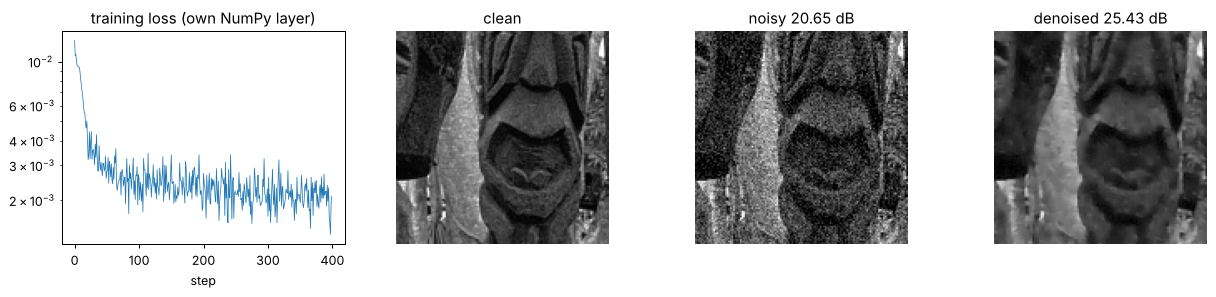

In [9]:
# A 3-layer denoiser built ONLY from the layer above: conv(1->16) ReLU conv(16->16) ReLU conv(16->1),
# trained to predict the noise residual (as DnCNN does) on 32x32 grayscale patches with sigma = 25.
import cv2
TRAIN_DIR = os.environ.get("BSD_TRAIN", "/kaggle/input/datasets/balraj98/berkeley-segmentation-dataset-500-bsds500/images/train")
VAL_DIR = os.environ.get("BSD_VAL", "/kaggle/input/datasets/balraj98/berkeley-segmentation-dataset-500-bsds500/images/val")
def gray(p): return cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2GRAY).astype(np.float64) / 255.0
train = [gray(p) for p in sorted(glob.glob(os.path.join(TRAIN_DIR, "*.jpg")))[:50]]
assert train, "set TRAIN_DIR to the BSD500 images/train folder"

def sample_batch(bs=16, size=32):
    out = np.empty((bs, 1, size, size))
    for i in range(bs):
        im = train[rng.integers(len(train))]; y0 = rng.integers(im.shape[0] - size); x0 = rng.integers(im.shape[1] - size)
        out[i, 0] = im[y0:y0 + size, x0:x0 + size]
    return out

def he(o, c, k=3): return rng.standard_normal((o, c, k, k)) * np.sqrt(2.0 / (c * k * k))
params = {"w1": he(16, 1), "b1": np.zeros(16), "w2": he(16, 16), "b2": np.zeros(16), "w3": he(1, 16) * 0.1, "b3": np.zeros(1)}

def forward(xn):
    h1, c1 = conv2d_forward(xn, params["w1"], params["b1"], 1, 1); a1, r1 = relu_forward(h1)
    h2, c2 = conv2d_forward(a1, params["w2"], params["b2"], 1, 1); a2, r2 = relu_forward(h2)
    v, c3 = conv2d_forward(a2, params["w3"], params["b3"], 1, 1)
    return v, (c1, r1, c2, r2, c3)

def backward(dv, caches):
    c1, r1, c2, r2, c3 = caches
    da2, g = {}, {}
    da2, g["w3"], g["b3"] = conv2d_backward(dv, c3)
    da1, g["w2"], g["b2"] = conv2d_backward(relu_backward(da2, r2), c2)
    _, g["w1"], g["b1"] = conv2d_backward(relu_backward(da1, r1), c1)
    return g

# Adam, written out (plain SGD also learns, just more slowly)
m = {k: np.zeros_like(v) for k, v in params.items()}; s2 = {k: np.zeros_like(v) for k, v in params.items()}
lr, beta1, beta2, sigma = 2e-3, 0.9, 0.999, 25 / 255
losses, t0 = [], time.perf_counter()
for step in range(1, 401):
    clean = sample_batch(); noise = sigma * rng.standard_normal(clean.shape); noisy = clean + noise
    pred, caches = forward(noisy)
    diff = pred - noise; loss = np.mean(diff ** 2); losses.append(loss)
    grads = backward(2 * diff / diff.size, caches)
    for k in params:
        m[k] = beta1 * m[k] + (1 - beta1) * grads[k]; s2[k] = beta2 * s2[k] + (1 - beta2) * grads[k] ** 2
        params[k] -= lr * (m[k] / (1 - beta1 ** step)) / (np.sqrt(s2[k] / (1 - beta2 ** step)) + 1e-8)
print(f"400 steps in {time.perf_counter() - t0:.0f} s; loss {np.mean(losses[:20]):.5f} -> {np.mean(losses[-20:]):.5f} "
      f"(predict-zero = sigma^2 = {sigma ** 2:.5f})")

# Before / after on a held-out validation crop
val = gray(sorted(glob.glob(os.path.join(VAL_DIR, "*.jpg")))[0])[100:228, 100:228]
noisy_v = val + sigma * np.random.default_rng(1).standard_normal(val.shape)
den_v = noisy_v - forward(noisy_v[None, None])[0][0, 0]
p = lambda a: 10 * np.log10(1 / np.mean((np.clip(a, 0, 1) - val) ** 2))
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
axes[0].plot(losses, lw=0.6); axes[0].set_yscale("log"); axes[0].set_title("training loss (own NumPy layer)"); axes[0].set_xlabel("step")
for ax, im, t in zip(axes[1:], [val, noisy_v, den_v], ["clean", f"noisy {p(noisy_v):.2f} dB", f"denoised {p(den_v):.2f} dB"]):
    ax.imshow(np.clip(im, 0, 1), cmap="gray", vmin=0, vmax=1); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()
print(f"held-out crop: noisy {p(noisy_v):.2f} dB -> denoised {p(den_v):.2f} dB (+{p(den_v) - p(noisy_v):.2f} dB)")

## Findings

- **Forward pass:** matches SciPy to 1e-10 on all three shape, stride and padding cases.
- **Backward pass:** my gradients match the numerical ones, with relative errors of 1.7e-10 to 6.9e-10 for `dx`, `dw` and `db` at strides 1 and 2. When I deliberately used the wrong kernel orientation, the error jumped to 0.71, so the check really does catch mistakes.
- **Rotated kernel:** for stride 1, the input gradient equals a full correlation with the kernel rotated 180°, which is the same as a full convolution with the kernel.
- **im2col:** 2× faster than my `tensordot` layer and 248× faster than pure Python loops. The cost is memory: its matrix is 9× the size of the input, because every pixel is copied k × k = 9 times.
- **NumPy denoiser:** the loss fell from 0.00798 to 0.00210 in 400 steps (always predicting zero scores 0.00961), and a held-out crop went from 20.65 dB to 25.43 dB (+4.77 dB). So my own layer can learn.